# 02 · Stage 1: themes (Task 1)

**Purpose:** show the categories, why this approach, and examples of calls in each, with the evidence and the weaknesses.  
**Decisions implemented:** D3, D3a, D8 (taxonomy v1).  
**Inputs → outputs:** `outputs/stage1/` (stability, taxonomy_v1.json, stage1_final.csv), `outputs/analysis/themes/`, `outputs/stage12_metrics.json`, `prompts/stage1_v1.md` → tables and charts.

*Run from the project root or from `notebooks/`; nothing is written, and no model is called (replay mode).*

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
from ti import nbhelpers as nb
nb.setup()
print("replay mode: no network, no API key, no spend")

replay mode: no network, no API key, no spend


## The approach (D3) and why

A clustering run with a *k* chosen on 100 calls is a one-time discovery technique, not a pipeline stage that can run every week: the categories would
shift under a dashboard. So the design is two parts:

1. **One-time discovery:** an LLM reads the transcripts and proposes candidate themes; a judgment call freezes a **versioned taxonomy** (v1).
2. **Recurring classification (the pipeline stage):** an LLM reads each transcript and assigns it to the frozen taxonomy with an evidence quote.
   A call that fits nothing goes to *Other / new theme*; a growing Other bucket is the signal to revise the taxonomy.

Input is the **transcript itself**. The dataset's provided summary and topics come from an upstream AI system we do not control, so they are a comparison baseline (below), not an input.
Each call gets a **theme** (what kind of conversation), a **product area** (which module) and an **incident** field (the March Detect outage as a cross-cutting thread).

## Discovery is unstable, so the human judgment is the real taxonomy

Two independent discovery runs proposed 12 and 10 themes. Matching each run-1 theme to its best run-2 theme, the mean overlap of the calls they cover (Jaccard) is 0.36 one way and 0.38 the other. Only 4 themes in each run match at or above 0.5.

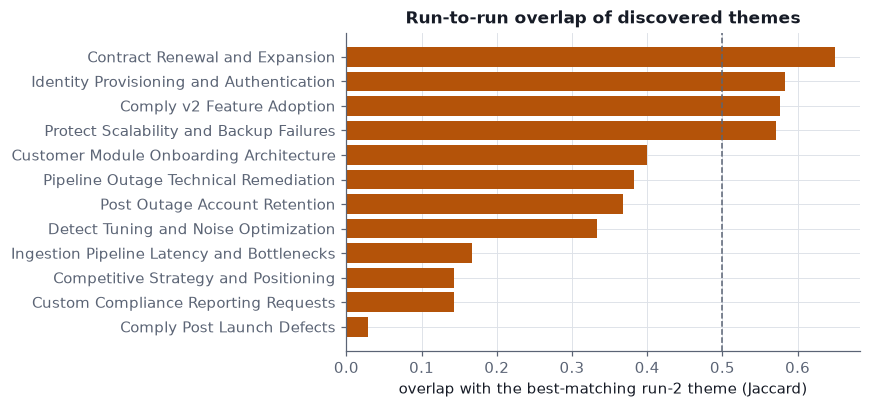

In [2]:
st = nb.read_json("outputs/stage1/stability.json")
pairs = pd.DataFrame(st["run1_to_run2"])
nb.md(f"Two independent discovery runs proposed {st['n_run1']} and {st['n_run2']} themes. Matching each run-1 theme to its best run-2 theme, "
      f"the mean overlap of the calls they cover (Jaccard) is {st['run1_to_run2_mean_best_jaccard']:.2f} one way and "
      f"{st['run2_to_run1_mean_best_jaccard']:.2f} the other. Only {st['run1_themes_with_match_ge_threshold']} themes in each run match at or above {st['threshold']}.")
fig, ax = plt.subplots(figsize=(8, 3.8))
p = pairs.sort_values("jaccard")
ax.barh(p.a_name.map(lambda s: nb.short(s, 44)), p.jaccard, color="#b45309")
ax.axvline(st["threshold"], color="#5b6475", ls="--", lw=1)
ax.set_xlabel("overlap with the best-matching run-2 theme (Jaccard)")
ax.set_title("Run-to-run overlap of discovered themes")
plt.tight_layout(); plt.show()

An LLM-proposed taxonomy is therefore a **starting point**. Taxonomy v1 (D8) was finalised under the candidate's delegation, with these changes from the pilot draft:
module-named themes (Identity, Backup) were merged into one technical-issues theme because *product area* is a separate field; owners were corrected
(onboarding to customer success, billing to the support lead with finance operations); routine internal meetings got their own theme
instead of sitting in *Other*; and an `incident` field was added so the outage story is visible across call types.

## The frozen taxonomy v1

In [3]:
tax = nb.read_json("outputs/stage1/taxonomy_v1.json")
nb.md(f"Version `{tax['version']}`, status: {tax['status']}.  \nOther policy: {tax['other_policy']}  \nTags: {tax['tags_rule']}")
nb.table(pd.DataFrame([{"theme": t["name"], "owner": t["owner"], "definition": t["definition"], "boundary note": t["boundary_note"]} for t in tax["themes"]]))
nb.table(pd.DataFrame(tax["product_areas"]).rename(columns={"name": "product area"}))

Version `v1`, status: frozen under delegation (DECISIONS.md D8).  
Other policy: Other / new theme only if no theme fits. More than 10% of calls in Other triggers a taxonomy revision (new version, full re-run).  
Tags: Up to two further themes from the list per call, besides one primary theme; a tag never repeats the primary theme.

theme,owner,definition,boundary note
Commercial Renewals and Retention,account manager / sales manager,"Renewals, contracts, pricing and SLA negotiation, churn risk, expansion deals.","If a call is mainly about product adoption with renewal as an aside, use Product Adoption, Feedback and Expansion."
"Product Adoption, Feedback and Expansion","product manager, customer success","Previews, launches, early access, roadmap input, feature requests, adoption and compliance-readiness reviews of the product, and internal launch-readiness reviews.","The module belongs in the product area field, not in the theme. Renewal talk that is only an aside stays here."
Incident and Outage Response,"engineering lead, support lead","War rooms, root cause, remediation plans, customer impact assessment, incident communication, postmortems, reliability reviews.",A single customer's technical fault that is not a platform incident belongs in Technical Integration and Performance Issues.
Technical Integration and Performance Issues,"support lead, engineering","Support-style troubleshooting: SSO, SAML, SCIM, LDAP, MFA failures, connectors and SIEM integration, backup windows and throughput, report defects, API errors, internal scalability concerns.",Module-specific problems go here with the module in the product area field. A platform-wide outage is Incident and Outage Response.
Onboarding and Implementation Scoping,customer success / solutions,"Kickoffs, deployment planning, architecture scoping, setup workshops.",Troubleshooting of an already deployed integration is Technical Integration and Performance Issues.
Billing and Usage Disputes,support lead with finance operations,"Invoices, overages, seat counts, billing adjustments.",Small theme (about 4 calls in the pilot); kept because it is distinct and actionable.
Competitive Strategy and Win/Loss,"sales leadership, product","Competitive intelligence, battlecards, win/loss analysis, and customer-facing calls where the customer is evaluating alternatives.",Definition widened from the pilot's internal-only version to include customer calls about evaluating alternatives.
Internal Planning and Delivery Cadence,engineering leads,"Standups, sprint planning, retros, all-hands, design and roadmap syncs with no customer or incident focus.","If a meeting is mainly an incident, use Incident and Outage Response."


product area,note
Detect,"Threat detection, event ingestion, alerting."
Comply,Compliance reporting and evidence mapping (including Comply v2).
Protect,"Backup, snapshots, disaster recovery (includes backup)."
Identity,"Directory sync, SSO, SAML, SCIM, MFA, IAM governance."
Platform/General,"No single product dominates, or the call is cross-product."


The classification prompt (the start of it; the full text, including the taxonomy and its boundary notes, is in `prompts/stage1_v1.md`):

In [4]:
nb.show_prompt("stage1_v1", max_chars=2400)

prompts/stage1_v1.md
- Version: stage1_v1
- Decision: D3, D3a, D8 (taxonomy v1, frozen under delegation)
- Input: full transcript with speaker sides, one call per request. No title, no call type, no provided summary, topics or score (`Meeting.view_for("stage1")`).
- Model and settings: D7 (google/gemini-3.8-flash, provider google-ai-studio, reasoning effort low, seed 7).
----------------------------------------------------------------------------------------------------
You classify one recorded call at Aegis Cloud Security, a B2B SaaS company, against a fixed theme taxonomy (version v1).

You receive the full transcript as numbered turns in the form "[index] Speaker (side): sentence". side is "customer" (works at an outside company) or "aegis_staff" (works at Aegis). You are given nothing else about the call: no title, no call type, no summary. Judge only from the words in the transcript.

THEMES (what kind of conversation it is; pick by what the call is mostly about):
1. Commercial R

## Results

All 100 calls were classified: 100 valid, 0 retries. Share placed in *Other / new theme*: **0.0%**. Evidence quotes that are exact substrings of the transcript: 99 of 100. Calls with at least one extra tag: 79.

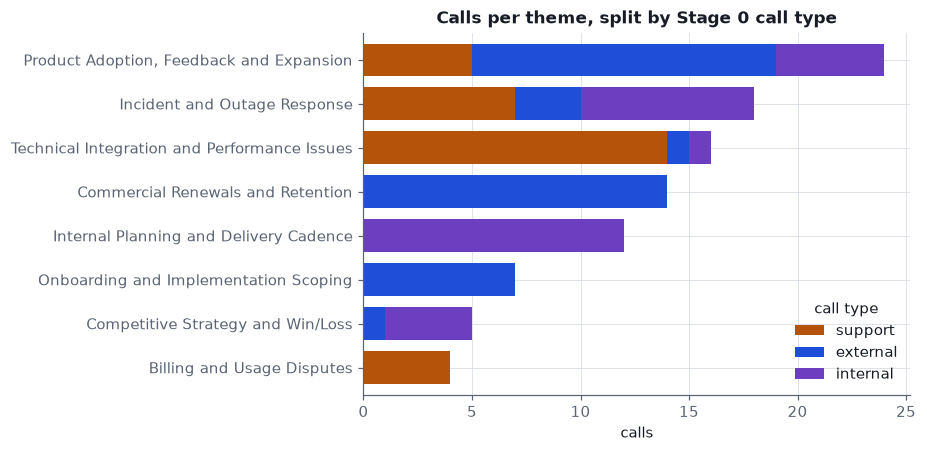

In [5]:
c = nb.calls()
m = nb.read_json("outputs/stage12_metrics.json")
s1 = m["stage1"]
nb.md(f"All {s1['n']} calls were classified: {s1['ok']} valid, {s1['retried']} retries. Share placed in *Other / new theme*: **{nb.pct(s1['other_share'])}**. "
      f"Evidence quotes that are exact substrings of the transcript: {s1['quote_exact']} of {s1['n']}. Calls with at least one extra tag: {s1['with_tags']}.")
order = c.primary_theme.value_counts().index.tolist()
ct = pd.crosstab(c.primary_theme, c.type).reindex(order)[nb.TYPES]
ax = ct.iloc[::-1].plot.barh(stacked=True, color=[nb.TYPE_COLORS[t] for t in nb.TYPES], figsize=(8.5, 4.2), width=0.75)
ax.set_title("Calls per theme, split by Stage 0 call type"); ax.set_xlabel("calls"); ax.set_ylabel("")
ax.legend(title="call type", frameon=False)
plt.tight_layout(); plt.show()

In [6]:
t = ct.copy(); t["total"] = t.sum(axis=1)
t["mean call score"] = c.groupby("primary_theme").call_score.mean().round(2)
t["mean customer score"] = c.groupby("primary_theme").customer_score.mean().round(2)
nb.table(t.reset_index().rename(columns={"primary_theme": "theme"}))
pa = pd.crosstab(c.product_area, c.type)[nb.TYPES]
pa["total"] = pa.sum(axis=1)
nb.table(pa.sort_values("total", ascending=False).reset_index().rename(columns={"product_area": "product area"}))

type,theme,support,external,internal,total,mean call score,mean customer score
,"Product Adoption, Feedback and Expansion",5,14,5,24,4.33,4.29
,Incident and Outage Response,7,3,8,18,2.47,2.10
,Technical Integration and Performance Issues,14,1,1,16,2.66,2.43
,Commercial Renewals and Retention,0,14,0,14,3.82,3.64
,Internal Planning and Delivery Cadence,0,0,12,12,3.75,–
,Onboarding and Implementation Scoping,0,7,0,7,4.57,4.57
,Competitive Strategy and Win/Loss,0,1,4,5,3.00,2.50
,Billing and Usage Disputes,4,0,0,4,3.62,3.62


type,product area,support,external,internal,total
,Detect,11,8,12,31
,Platform/General,1,14,7,22
,Comply,5,10,6,21
,Identity,7,5,3,15
,Protect,6,3,2,11


**Reading it as a stakeholder.** *Technical Integration* is the support lead's queue; *Incident and Outage Response* is where engineering, support and internal calls meet;
*Commercial Renewals* is entirely external and is the sales manager's exposure to the outage (next table).

### The incident field: two numbers, not one

The `incident` field marks a call that is *mainly or substantially* about the March Detect outage. It is an LLM judgment, partly definitional; in the candidate's 20-call check it missed 3 and never over-flagged, so 42 is probably a floor. Analyses therefore report two versions: **core** (the theme itself is *Incident and Outage Response*) and **touches** (the field is set).

In [7]:
inc = pd.DataFrame({
    "core (theme = Incident and Outage Response)": c[c.core_incident].type.value_counts().reindex(nb.TYPES).fillna(0).astype(int),
    "touches (incident field set)": c[c.touches_incident].type.value_counts().reindex(nb.TYPES).fillna(0).astype(int),
})
inc.loc["all"] = inc.sum()
nb.table(inc.reset_index().rename(columns={"index": "call type"}))

type,core (theme = Incident and Outage Response),touches (incident field set)
support,7,10
external,3,18
internal,8,14
all,18,42


## Examples: a clear and a borderline call per theme

Quotes are the model's own evidence quotes, verbatim from the transcript. The borderline rows are where a reasonable person could disagree, which is where the hand-check should look.

In [8]:
ex = nb.read_json("outputs/analysis/themes/examples.json")
rows = []
for theme, lst in ex.items():
    for kind in ("clear", "borderline"):
        x = next((e for e in lst if e["kind"] == kind), None)
        if x:
            rows.append({"theme": theme, "kind": kind, "call": nb.short(x["title"], 58), "type": x["type"],
                         "evidence quote": nb.short(x["quote"], 150), "why": nb.short(x["why"], 110)})
nb.table(pd.DataFrame(rows))

theme,kind,call,type,evidence quote,why
Billing and Usage Disputes,clear,Support Case #9279 - Summit Trust Billing Inquiry,support,"Yeah so, uh, we received our January invoice last week and there's a line item on there that doesn't quite match what we expected based on our contra…",High confidence; the provided topics point to the same theme; 1 extra tag(s).
Billing and Usage Disputes,borderline,Support Case #7570 - Silverline Brands Comply v2 License…,support,And basically the issue is we upgraded to Comply v2 when it launched on the seventh and we're seeing a billing discrepancy that we can't quite figure…,"also tagged: Product Adoption, Feedback and Expansion; the provided topics alone would suggest 'Product Adopt…"
Commercial Renewals and Retention,clear,Aegis / Blackridge Investments - Renewal Discussion,external,"I was thinking we'd kind of do a quick check-in on how the platform's been performing for you this year, and then we can talk about the renewal terms…",High confidence; the provided topics point to the same theme; 1 extra tag(s).
Commercial Renewals and Retention,borderline,Aegis / Atlas Precision - Contract Discussion,external,"Your current contract runs through end of March, so we wanted to get ahead of it a bit, talk through the current structure, see if anything needs to…","also tagged: Billing and Usage Disputes; Product Adoption, Feedback and Expansion; the provided topics alone…"
Competitive Strategy and Win/Loss,clear,Competitive Threat Assessment - Post Outage,internal,"So, let's talk competitive positioning because that's really why we're on this call.",High confidence; the provided topics point to the same theme; 2 extra tag(s).
Competitive Strategy and Win/Loss,borderline,Aegis / Brightpath Commerce - Competitive Evaluation,external,"Because honestly Aisha, I'll just be upfront with you, we've been doing a broader security vendor evaluation over the last six weeks or so and it's b…",also tagged: Commercial Renewals and Retention; Incident and Outage Response; the provided topics alone would…
Incident and Outage Response,clear,Detect Outage - Remediation Plan Review,internal,"So, uh, the reason I wanted to get us together today — obviously we're still in the middle of this, day three of the outage window — I want to make s…",High confidence; the provided topics point to the same theme; 0 extra tag(s).
Incident and Outage Response,borderline,INCIDENT: Detect Pipeline Failure - War Room,internal,"So, uh, at approximately 9:14 AM Pacific we started seeing alerts — or rather, the absence of alerts — from the Detect event processing pipeline.",the provided topics alone would suggest 'Technical Integration and Performance Issues'
Internal Planning and Delivery Cadence,clear,Weekly Engineering Standup,internal,"Okay, so usual format — let's do a quick status round, then I want to spend some time on the Detect pipeline work and the Comply v2 timeline.",High confidence; the provided topics point to the same theme; 0 extra tag(s).
Internal Planning and Delivery Cadence,borderline,All Hands - April Update,internal,"So I want to cover a few things — we'll do a quick retrospective on the March Detect outage, then talk about the Comply v2 launch, and then get into…","also tagged: Incident and Outage Response; Product Adoption, Feedback and Expansion; the provided topics alon…"


## Comparison with the dataset's own topics

The dataset ships free-text topic strings from an upstream AI system. They overlap heavily, so they cannot be used as categories directly. As a **consistency check** (not accuracy), can our theme be predicted from them alone?

The 100 calls carry 600 provided topic tags in 351 distinct strings (266 used once). A leave-one-out nearest-centroid on those strings alone recovers our theme for **76%** of calls.

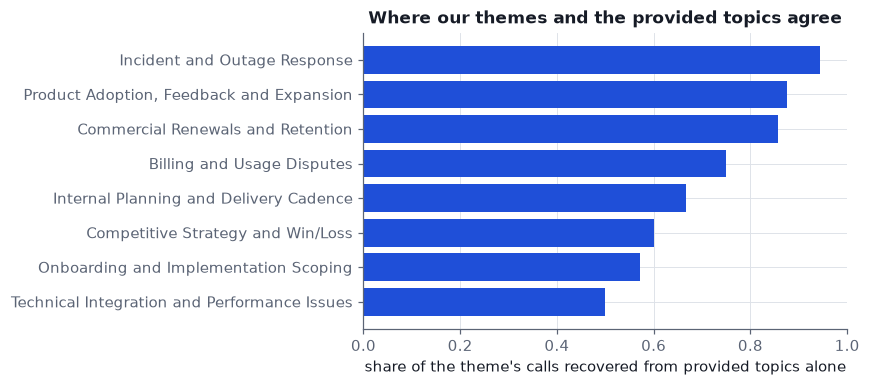

Largest disagreements (our theme → theme implied by the provided topics):

our theme,implied by provided topics,calls
Technical Integration and Performance Issues,Incident and Outage Response,7
Onboarding and Implementation Scoping,"Product Adoption, Feedback and Expansion",2
"Product Adoption, Feedback and Expansion",Onboarding and Implementation Scoping,2
Billing and Usage Disputes,"Product Adoption, Feedback and Expansion",1
Commercial Renewals and Retention,Billing and Usage Disputes,1


In [9]:
from ti.load import load_meetings
ms = load_meetings()
tag_counts = pd.Series([t for m in ms for t in m.provided.topics]).value_counts()
ts = nb.read_json("outputs/analysis/themes/summary.json")
nb.md(f"The {len(ms)} calls carry {int(tag_counts.sum())} provided topic tags in {len(tag_counts)} distinct strings ({int((tag_counts == 1).sum())} used once). "
      f"A leave-one-out nearest-centroid on those strings alone recovers our theme for **{nb.pct(ts['loo_accuracy'], 0)}** of calls.")
rec = pd.Series(ts["loo_recall"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([nb.short(k, 46) for k in rec.index], rec.values, color="#1f4fd8")
ax.set_xlim(0, 1); ax.set_xlabel("share of the theme's calls recovered from provided topics alone")
ax.set_title("Where our themes and the provided topics agree")
plt.tight_layout(); plt.show()
cf = pd.read_csv(ROOT / "outputs/analysis/themes/ours_vs_provided_topics_confusion.csv", index_col=0)
off = sorted([(a, b, int(cf.loc[a, b])) for a in cf.index for b in cf.columns if a != b and cf.loc[a, b] > 0], key=lambda t: -t[2])[:5]
nb.md("Largest disagreements (our theme → theme implied by the provided topics):")
nb.table(pd.DataFrame(off, columns=["our theme", "implied by provided topics", "calls"]))

The biggest one is the boundary between *Technical Integration* and *Incident and Outage*: a single customer's technical fault versus a platform event. That is the most likely place for the hand-check to disagree with the model.

## Sanity checks

Each theme was expected to concentrate in one call type (billing and integration in support, renewals in external, planning in internal). **These expectations were written together with the theme definitions, so passing is partly by construction.**

In [10]:
sc = pd.read_csv(ROOT / "outputs/analysis/themes/sanity_checks.csv")
sc["share_in_expected"] = sc.share_in_expected.map(nb.pct)
nb.table(sc)

theme,expected_type,n,share_in_expected,threshold,passed
Billing and Usage Disputes,support,4,100.0%,0.5,True
Technical Integration and Performance Issues,support,16,87.5%,0.5,True
Commercial Renewals and Retention,external,14,100.0%,0.5,True
Internal Planning and Delivery Cadence,internal,12,100.0%,0.5,True


## Stability of the recurring stage, and the caveats that matter

In [11]:
ss = m["stage1_stability"]
nb.md(f"Re-running Stage 1 on a seeded sample of {ss['n']} calls (stratified by call type): primary theme identical on {nb.pct(ss['primary_theme_agreement'], 0)}, "
      f"product area on {nb.pct(ss['product_area_agreement'], 0)}, incident field on {nb.pct(ss['incident_agreement'], 0)}; tag sets overlap {ss['tag_set_mean_jaccard']:.2f} (Jaccard).")
nb.md(f"""
**Caveats to keep in view**

- **Other = {nb.pct(s1['other_share'])} proves nothing.** Models rarely use an "Other" bucket, so the safeguard "more than 10% in Other triggers a taxonomy revision" has **not been tested** here.
- **Tags are liberal.** {s1['with_tags']} of {s1['n']} calls carry at least one extra tag, so tags are weak evidence of a second theme; headline numbers use the primary theme only.
- **Quote length.** Only {s1['quote_within_30_words']} of {s1['n']} quotes respect the prompt's 30-word limit; they are verbatim, but the length rule is not followed.
- **The taxonomy was derived from the same calls it is applied to**, and was partly shaped by a pilot assignment of those calls.
- **Theme and product area overlap** for some themes (the incident theme is all Detect), so they are not independent.
""")

Re-running Stage 1 on a seeded sample of 20 calls (stratified by call type): primary theme identical on 100%, product area on 100%, incident field on 100%; tag sets overlap 0.95 (Jaccard).


**Caveats to keep in view**

- **Other = 0.0% proves nothing.** Models rarely use an "Other" bucket, so the safeguard "more than 10% in Other triggers a taxonomy revision" has **not been tested** here.
- **Tags are liberal.** 79 of 100 calls carry at least one extra tag, so tags are weak evidence of a second theme; headline numbers use the primary theme only.
- **Quote length.** Only 60 of 100 quotes respect the prompt's 30-word limit; they are verbatim, but the length rule is not followed.
- **The taxonomy was derived from the same calls it is applied to**, and was partly shaped by a pilot assignment of those calls.
- **Theme and product area overlap** for some themes (the incident theme is all Detect), so they are not independent.


## Hand-check (the candidate's own review)

20 calls, my own review (small sample; the console offered a blind mode, but I cannot confirm I stayed blind to the model answers): theme, product area and incident yes/no.

In [12]:
items = nb.load_verdicts(1)
if items is None:
    nb.pending_notice(1)
else:
    d, s = nb.stage1_handcheck(items)
    nb.md(f"Hand-check (candidate's own review) of {s['n']} calls: theme agreement **{nb.pct(s['theme'])}**, product area **{nb.pct(s['product_area'])}**, incident field **{nb.pct(s['incident'])}**.")
    nb.table(d[~(d.theme_ok & d.area_ok & d.incident_ok)])

Hand-check (candidate's own review) of 20 calls: theme agreement **100.0%**, product area **95.0%**, incident field **85.0%**.

meeting,type,you_theme,model_theme,you_area,model_area,you_incident,model_incident,theme_ok,area_ok,incident_ok
Weekly Engineering Standup,internal,Incident and Outage Response,Incident and Outage Response,Detect,Detect,True,False,True,True,False
Support Case #3266 - Trailhead Marketplace Detect Alerts Not,support,Incident and Outage Response,Incident and Outage Response,Detect,Detect,True,False,True,True,False
Aegis / Nova Retail Group - Renewal Discussion,external,Commercial Renewals and Retention,Commercial Renewals and Retention,Detect,Platform/General,True,False,True,False,False
